In [3]:
import os
import cv2
import numpy as np

# Base path where the directories are located
base_path = '/kaggle/input/mmu-iris/MMU/'

data = []
labels = []

for subject in range(1, 47):  # For directories 1 to 46
    for eye in ['left', 'right']:
        eye_path = os.path.join(base_path, f'{subject}', eye)
        if not os.path.exists(eye_path):
            print(f"Directory {eye_path} does not exist, skipping...")
            continue  # Skip to the next iteration if the directory doesn't exist
        
        for img_name in os.listdir(eye_path):
            img_path = os.path.join(eye_path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            
            if img is None:
                print(f"Failed to load image {img_path}, skipping...")
                continue  # Skip to the next image if it fails to load

            img_resized = cv2.resize(img, (64, 64))  # Resize to 64x64 pixels
            data.append(img_resized)
            labels.append(f'{subject}_{eye}')  # Label as subject_left or subject_right

data = np.array(data)
labels = np.array(labels)

print("Data and labels loaded successfully!")


Directory /kaggle/input/mmu-iris/MMU/1\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/1\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/2\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/2\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/3\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/3\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/4\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/4\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/5\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/5\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/6\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/6\right does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/7\left does not exist, skipping...

Directory /kaggle/input/mmu-iris/MMU/7\right 

In [4]:
from sklearn.model_selection import train_test_split

# Normalize the data
data = data / 255.0  # Rescale pixel values to the range [0, 1]

# Reshape the data to fit the CNN input requirements
data = data.reshape(data.shape[0], 64, 64, 1)  # Add channel dimension

# Convert labels to a numerical format
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical

label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)
labels_categorical = to_categorical(labels_encoded)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(data, labels_categorical, test_size=0.2, random_state=42)

print("Data split into training and testing sets!")


KeyboardInterrupt: 

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Build the CNN model
model = Sequential()

# First convolutional layer
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second convolutional layer
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Third convolutional layer
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the results to feed into a dense layer
model.add(Flatten())

# Fully connected layer
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

# Output layer
model.add(Dense(len(np.unique(labels)), activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("CNN model built successfully!")


/opt/conda/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.

  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN model built successfully!


In [7]:
# Train the model
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_test, y_test), batch_size=32)

print("Model training complete!")


Epoch 1/20


2024-08-12 13:28:02.899320: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3844: 3.50622, expected 2.90338

2024-08-12 13:28:02.899393: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3845: 2.89383, expected 2.29098

2024-08-12 13:28:02.899405: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3846: 2.45266, expected 1.84981

2024-08-12 13:28:02.899417: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3847: 3.22924, expected 2.6264

2024-08-12 13:28:02.899430: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3848: 3.88833, expected 3.28549

2024-08-12 13:28:02.899448: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3849: 4.2225, expected 3.61966

2024-08-12 13:28:02.899459: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3850: 3.66357, expected 3.06072

2024-08-12 13:28:02.899470: E

 1/12 ━━━━━━━━━━━━━━━━━━━━ 1:10 6s/step - accuracy: 0.0000e+00 - loss: 4.4855


I0000 00:00:1723469285.878527     141 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.

W0000 00:00:1723469285.901543     141 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update

2024-08-12 13:28:06.787641: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 2.76921, expected 2.228

2024-08-12 13:28:06.787713: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1: 2.68882, expected 2.14761

2024-08-12 13:28:06.787726: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2: 1.92533, expected 1.38412

2024-08-12 13:28:06.787740: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3: 2.61092, expected 2.0697

2024-08-12 13:28:06.787758: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 3.28671, expected 2.7455

2024-08-12 13:28:06.787771: E external/l

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.0130 - loss: 4.5280   

W0000 00:00:1723469289.053097     139 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update

W0000 00:00:1723469289.747840     140 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update

2024-08-12 13:28:09.850763: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 0: 2.63447, expected 1.89622

2024-08-12 13:28:09.850836: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 1: 2.62393, expected 1.88567

2024-08-12 13:28:09.850846: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 2: 2.16773, expected 1.42948

2024-08-12 13:28:09.850854: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 3: 1.85166, expected 1.1134

2024-08-12 13:28:09.850862: E external/local_xla/xla/service/gpu/buffer_comparator.cc:1137] Difference at 4: 3.01544, expected 2.27718

2024-08-12 13:28:09.850870: E external/local_xla/xla/service/gpu/buff

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 415ms/step - accuracy: 0.0131 - loss: 4.5278 - val_accuracy: 0.0000e+00 - val_loss: 4.5126

Epoch 2/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0221 - loss: 4.5014 - val_accuracy: 0.0000e+00 - val_loss: 4.5200

Epoch 3/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0079 - loss: 4.4965 - val_accuracy: 0.0000e+00 - val_loss: 4.5105

Epoch 4/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0104 - loss: 4.4954 - val_accuracy: 0.0000e+00 - val_loss: 4.5333

Epoch 5/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0082 - loss: 4.5020 - val_accuracy: 0.0000e+00 - val_loss: 4.5382

Epoch 6/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0143 - loss: 4.4840 - val_accuracy: 0.0000e+00 - val_loss: 4.5824

Epoch 7/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0216 - loss: 4.4363 - val_accuracy: 0.0000e+00 - val_loss: 4.5938

Epoch 8/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0224 - loss: 4.3763 

In [8]:
model = Sequential()

model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Additional convolutional layer
model.add(Conv2D(256, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())

model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(len(np.unique(labels)), activation='softmax'))


In [10]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train)

# Train the model using data augmentation
history = model.fit(datagen.flow(X_train, y_train, batch_size=32),
                    validation_data=(X_test, y_test),
                    epochs=20)


Epoch 1/20


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.

  self._warn_if_super_not_called()


12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 403ms/step - accuracy: 0.0074 - loss: 4.5200 - val_accuracy: 0.0222 - val_loss: 4.5108

Epoch 2/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0062 - loss: 4.5007 - val_accuracy: 0.0000e+00 - val_loss: 4.5189

Epoch 3/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0154 - loss: 4.4978 - val_accuracy: 0.0000e+00 - val_loss: 4.5372

Epoch 4/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0084 - loss: 4.4888 - val_accuracy: 0.0111 - val_loss: 4.5754

Epoch 5/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0146 - loss: 4.4889 - val_accuracy: 0.0000e+00 - val_loss: 4.6329

Epoch 6/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0145 - loss: 4.4723 - val_accuracy: 0.0000e+00 - val_loss: 4.5935

Epoch 7/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0118 - loss: 4.4768 - val_accuracy: 0.0000e+00 - val_loss: 4.6634

Epoch 8/20

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0110 - loss: 4.4795 -

In [2]:
import squarify 
import os
import PIL
import math
import cv2
import random
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

## Data modeling
import tensorflow as tf
from keras import Sequential
from sklearn.model_selection import cross_val_score
from keras import backend as K
from tensorflow import keras as keras
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, roc_curve, auc, roc_auc_score,  roc_curve, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Layer, Input, Dense,Dropout, Conv2D, BatchNormalization, Flatten, Input, Conv2D, GaussianNoise,MaxPooling2D, Flatten, Dense, Dropout

### Model evaluatoin
from torchmetrics import Precision, Recall, Accuracy, AUROC
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module='sklearn.metrics')

from scipy.optimize import brentq
from scipy.interpolate import interp1d

import logging
import time
from glob import glob

In [3]:
def load_dataset(path):
    """
    Loading the dataset into a pandas datframe.
    The images of CASIA-Iris-Thousand are stored as:    /CASIA-Iris-Thousand/YYY/E/S5YYYENN.jpg

        YYY: the unique identifier of the subject in the subset
        E: ‘L’ denotes left eye and ‘R’ denotes right eye
        NN: the index of the image in the class
    
    Args:
        path(str): string that has the path of the dataset
    Returns:
        df(pd.DataFrame): the loaded dataframe
    """
    labels = []
    images = []

    for folder in os.listdir(path):
        for lr in os.listdir(path+'/'+folder): #left or right
            for image in os.listdir(path+'/'+folder+'/'+lr):
                if image.endswith('b') is False:
                    images.append(path+'/'+folder+'/'+lr+'/'+image)
                    labels.append(folder+'-'+lr) #+'-'+lr

    df = pd.DataFrame(list(zip(labels, images)), columns=['Label', 'ImagePath'])
    return df, labels, images

In [4]:
df, labels, images = load_dataset('/kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand')

In [5]:
def missing_values(df):
    """
    This is to get the percetages of missing data
    Args:
        df (pd.Dataframe): contains the data
    Returns:
        missing_percetanges(pd.Dataframe): contains Column,	Counts, and	Percentage
            of the missing values for eah colmn
    """
    missing_count = df.isnull().sum()
    missing_percetanges = pd.DataFrame({
        'Column': missing_count.index,
        'Counts': missing_count.values,
        'Percentage': (missing_count.values / len(df)) * 100  
    })
    return  missing_percetanges

In [6]:
def explore_data(df):
    """
    Exploring a dataset sample
    Args:
        sample (pd.Dataframe): the dataset sample to explore.
    Returns:
        results (dict): containing results of each exploration with the title as key
    """
    head = pd.DataFrame(df.head())
    tail = pd.DataFrame(df.tail())
    nunique = pd.DataFrame(df.nunique(), columns=["#_of_Unique"])
    describe = pd.DataFrame(df.describe())
    dtypes =  pd.DataFrame(df.dtypes, columns=["Datatype"])
    labels_distribution = pd.DataFrame(df['Label'].value_counts())
    results = {
        'Table 2: Dataset Head:':head,
        'Table 3: Dataset Tail:':tail,
        'Table 4: Dataset Numerical Describtion: ':describe,
        'Table 5: Missing Values By Percentage': missing_values(df), 
        'Table 6: Dataset Columns Data types: ':dtypes,
        'Table 7: Number of uniques in the datasets:':nunique,
        'Table 8: Labels Distribution:':labels_distribution}
    return results

In [7]:
def print_dataset_exploration(results):
    """
    Prints a beautufil display of each of the exploration dataframe
    Args:
        results (dict): contains exploration outputs with the title as key
    Returns:
        nothing
    """
    for operation, dataframe in results.items():
        print(f"{operation}")
        if operation == 'Table 6: Missing Values By Percentage':
            print("Total Sum of Missing Percetange: ", dataframe['Percentage'].sum())
        display(dataframe)

In [8]:
print_dataset_exploration(explore_data(df))

Table 2: Dataset Head:


,Label,ImagePath
0,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
1,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
2,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
3,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
4,437-R,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...


Table 3: Dataset Tail:


,Label,ImagePath
19995,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
19996,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
19997,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
19998,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
19999,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...


Table 4: Dataset Numerical Describtion: 


,Label,ImagePath
count,20000,20000
unique,2000,20000
top,715-L,/kaggle/input/casia-iris-thousand/CASIA-Iris-T...
freq,10,1


... (4 outputs left out)

Table 7: Number of uniques in the datasets:


,#_of_Unique
Label,2000
ImagePath,20000


Table 8: Labels Distribution:


,count
Label,
715-L,10
437-R,10
437-L,10
515-R,10
515-L,10
...,...
768-L,10
642-R,10
642-L,10


In [9]:
def show_random_samples(df, num):
    """
    Shows a sample on the dataframe in a specific location.
    Args:
        df (pd.DataFrame): the dataset
        num (int): the number of random samples to display
    Return:
        Nothing but shows a sample in the display
    """
    random.seed(1190652)
    random_indices = random.sample(range(df.shape[0]), num)
    num_rows = math.ceil(num / 4) 

    fig, axes = plt.subplots(num_rows, 4, figsize=(20, num_rows * 5))  
    for i, idx in enumerate(random_indices):
        row = i // 4
        col = i % 4
        
        if idx < df.shape[0]:  
            image_path =  df.loc[idx, "ImagePath"]
            image = PIL.Image.open(image_path)
            ax = axes[row, col] if num_rows > 1 else axes[col]
            ax.imshow(image, cmap='gray')
            ax.set_title(f"Image {idx} Person Label: {df.loc[idx, 'Label']}")
            ax.axis("off")

    plt.suptitle("Figure 3: Random Small Sample of the Dataset")
    plt.tight_layout()
    plt.show()

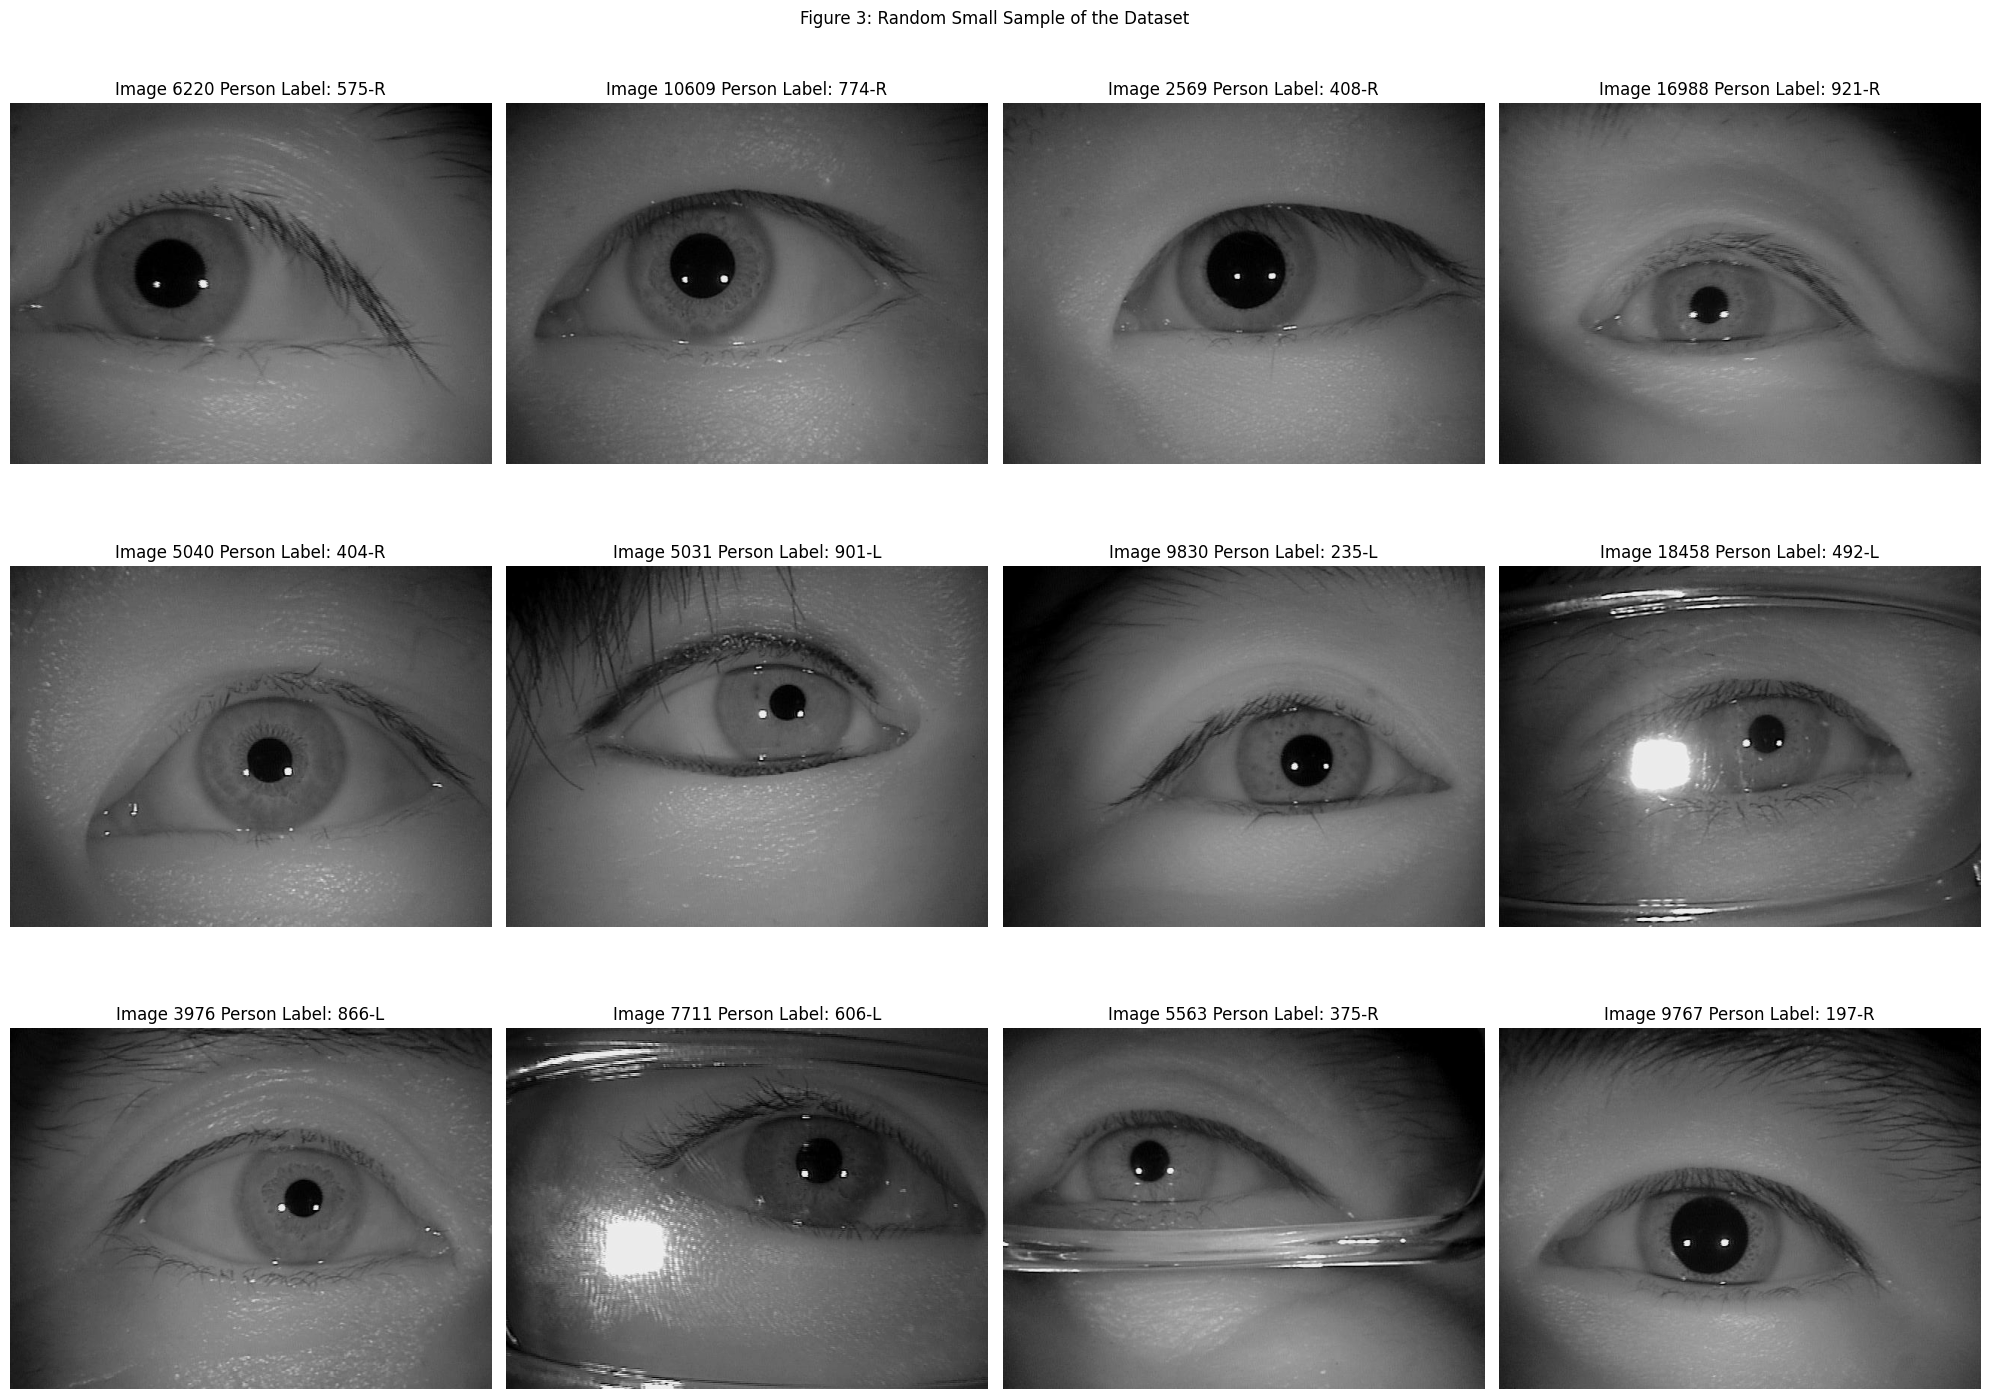

In [10]:
show_random_samples(df, 12)

The width of the images:  640
The height of the images:  480
Shape (640, 480)


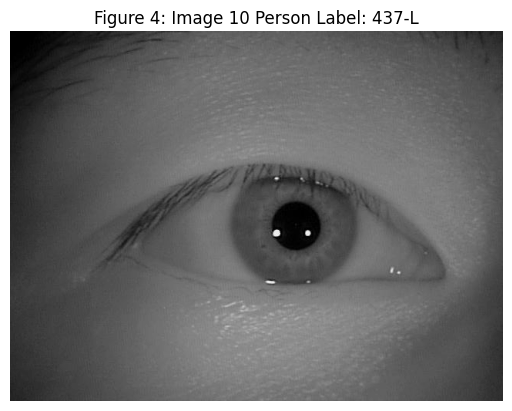

In [11]:
image_path =  df.loc[10, "ImagePath"]
image = PIL.Image.open(image_path)
plt.imshow(image, cmap='gray')
plt.title(f"Figure 4: Image {10} Person Label: {df.loc[10, 'Label']}")
plt.axis("off")
width, height = image.size
print("The width of the images: ", width)
print("The height of the images: ", height)
print("Shape", image.size)

In [13]:
image_sizes = []
aspect_ratios = []

for image_path in df['ImagePath']:
    image = PIL.Image.open(image_path)
    width, height = image.size
    image_sizes.append(width * height)
    aspect_ratios.append(width / height)

Text(0, 0.5, 'Frequency')

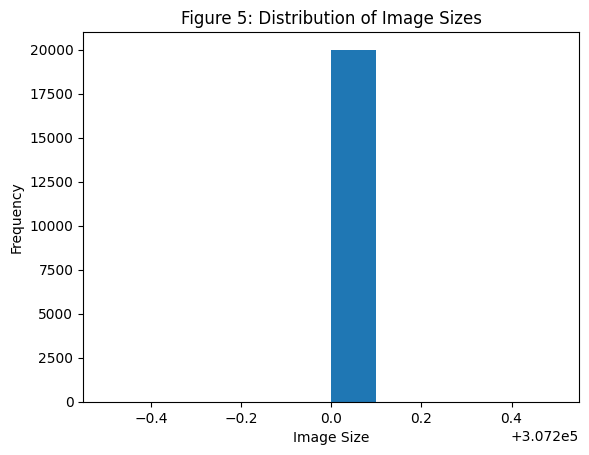

In [14]:
plt.hist(image_sizes, label="Image Size")
plt.title("Figure 5: Distribution of Image Sizes")
plt.xlabel("Image Size")
plt.ylabel("Frequency")

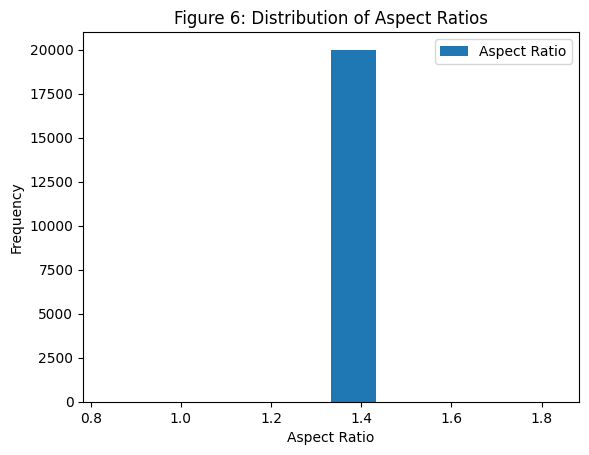

In [15]:
plt.hist(aspect_ratios, label="Aspect Ratio")
plt.title("Figure 6: Distribution of Aspect Ratios")
plt.xlabel("Aspect Ratio")
plt.ylabel("Frequency")
plt.legend()

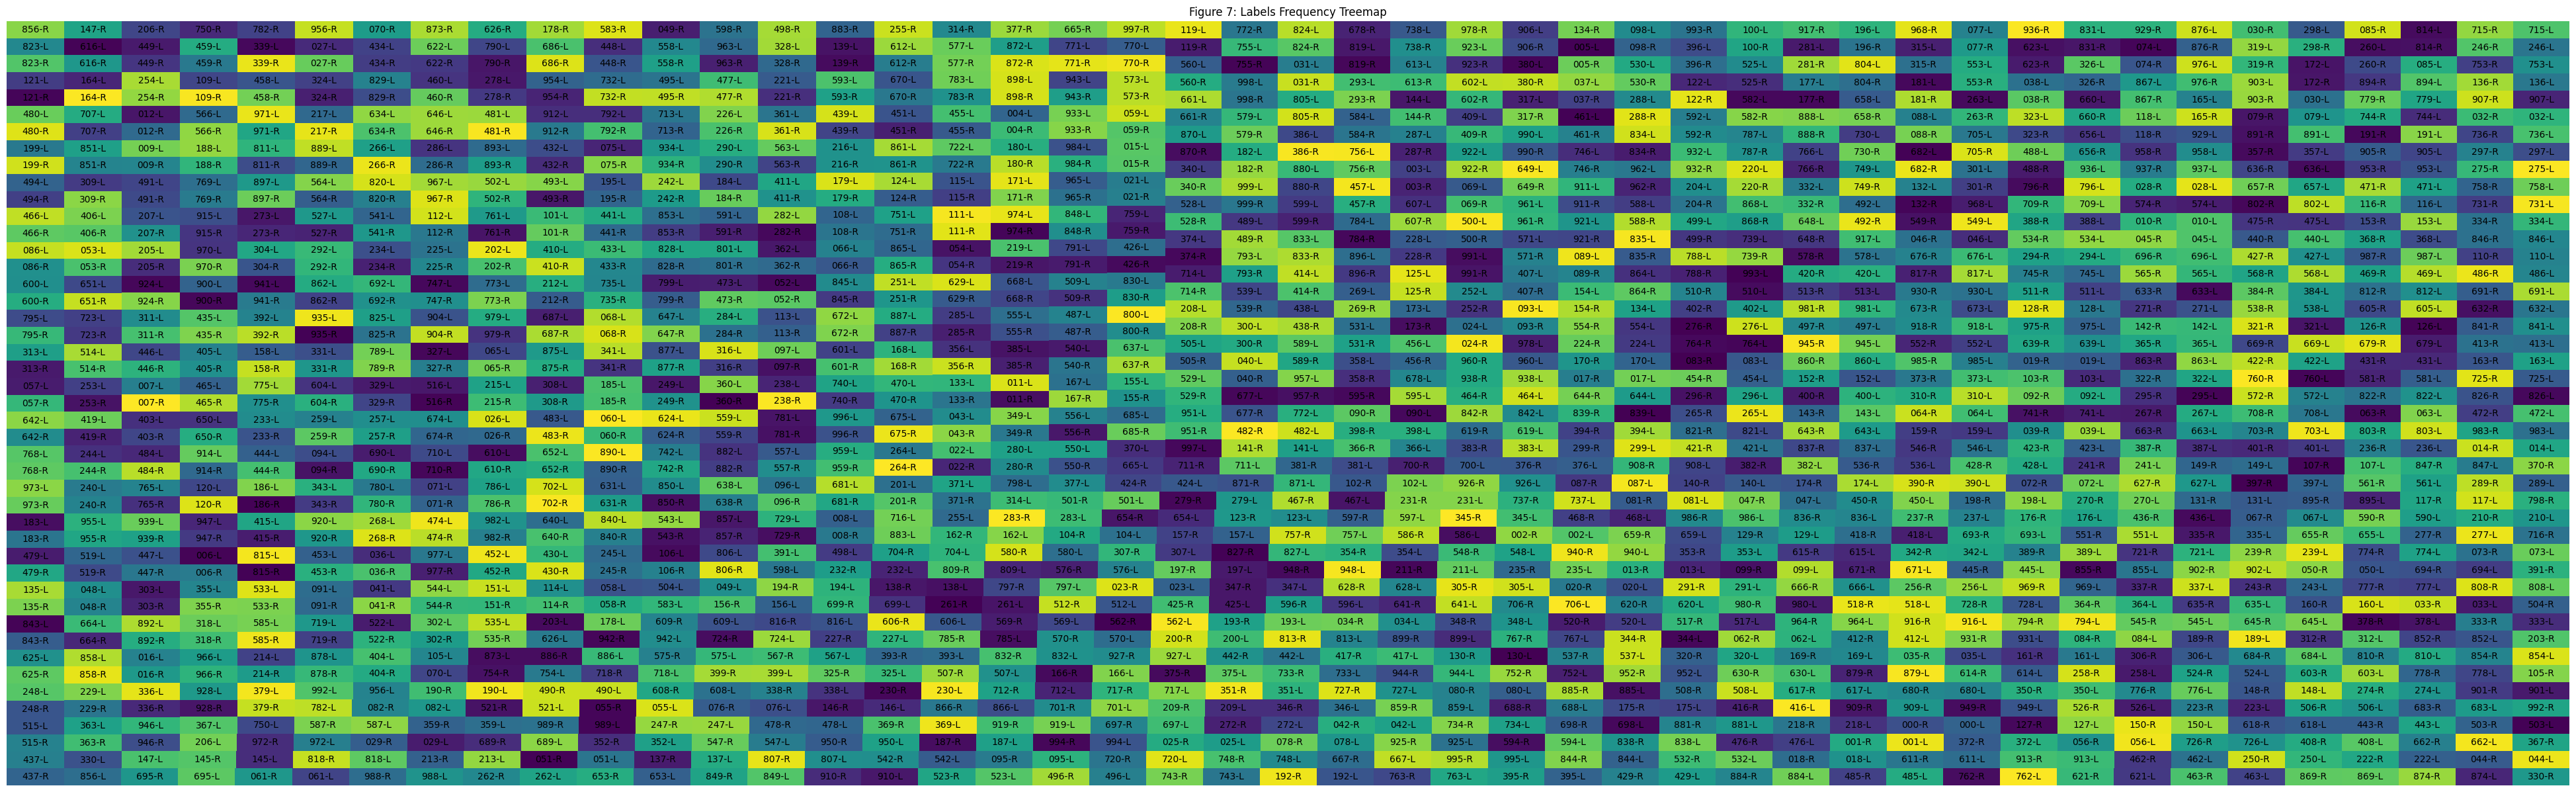

In [16]:
plt.figure(figsize=(50, 15))
squarify.plot(sizes=df['Label'].value_counts(), label=df['Label'].unique())
plt.axis('off')
plt.title('Figure 7: Labels Frequency Treemap')
plt.show()

In [17]:
# Dataset Config
SIZE = 20000
NUM_CLASSES = 2000
IMG_HEIGHT = 150
IMG_WIDTH = 150
NUM_CHANNELS = 1
input_shape=(IMG_HEIGHT, IMG_WIDTH, NUM_CHANNELS)

In [18]:
def resize_keep_aspect_ration(img, target_height=IMG_HEIGHT, target_width=IMG_WIDTH, pad_value=255):
    """
    Resize an image to a specific size keeping the aspect ratio using padding
    Args:
        - img (np.array): image
        - target_height (int): with the deafult value as IMG_HEIGHT
        - target_width (int): with the deafult value as IMG_WIDTH
        - pad_value (int): the padding value foe the left of the image with the deafult value is 255
    Returns:
        - The resized image
    """
    aspect_ratio = img.shape[1] / img.shape[0]
    
    ## Get the new sizes with keeping the aspect ratio
    if aspect_ratio > target_width / target_height:
        new_width = target_width
        new_height = int(target_width / aspect_ratio)
    else:
        new_height = target_height
        new_width = int(target_height * aspect_ratio)

    resized_img = cv2.resize(img, (new_width, new_height))
    
    ## Padding up and down so the image is in the middle
    preprocessed_img = np.full((target_height, target_width), pad_value, dtype=np.uint8)
    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2
    preprocessed_img[y_offset:y_offset + new_height, x_offset:x_offset + new_width] = resized_img
    
    return preprocessed_img

In [19]:
def preprocess_image(img_dir):
    """
    Resizing imgaes with keeping the aspect ratio.
    Args:
        img_dir(str): Image path on the dataset
        target_height(int): the targeted height to be resized
        target_width(int): the targeted width to be resized
        pad_value(int): used as the padding value for the resized image
    Returns:
        preprocessed_img (cv.Imgae): processsed image
    """
    img = cv2.imread(img_dir, cv2.IMREAD_GRAYSCALE)
    img = resize_keep_aspect_ration(img)
    img = img/255.
    
    return img

<function matplotlib.pyplot.show(close=None, block=None)>

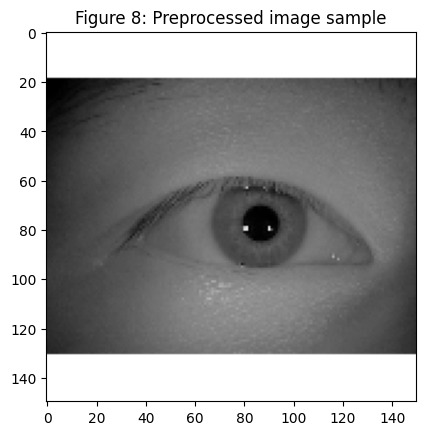

In [20]:
plt.imshow(preprocess_image(df.iloc[10]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

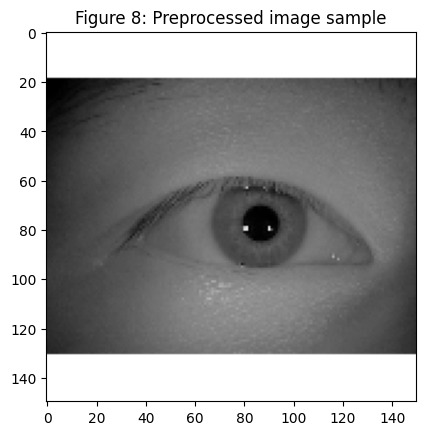

In [21]:
plt.imshow(preprocess_image(df.iloc[10]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

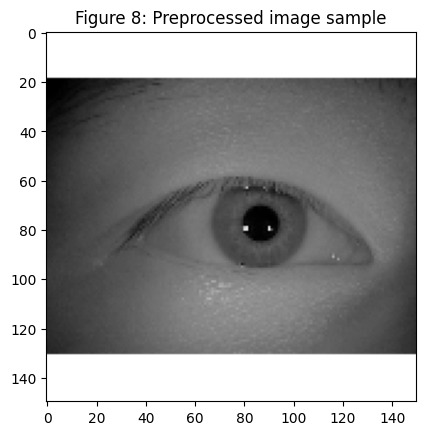

In [22]:
plt.imshow(preprocess_image(df.iloc[10]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

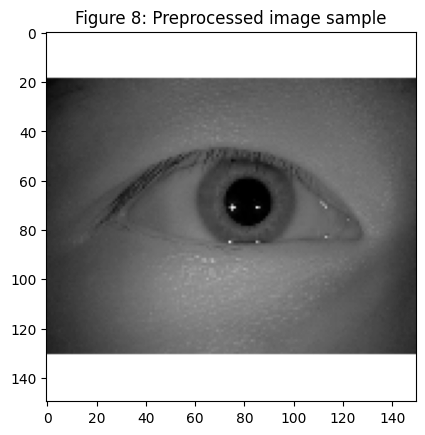

In [23]:
plt.imshow(preprocess_image(df.iloc[15]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

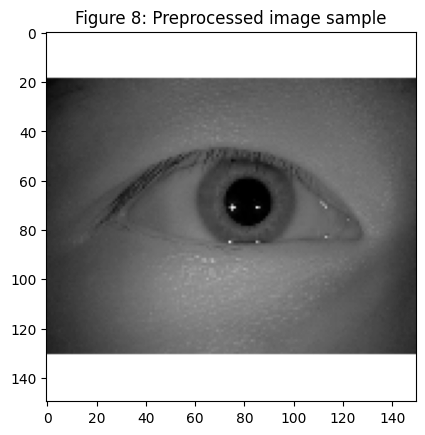

In [24]:
plt.imshow(preprocess_image(df.iloc[15]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

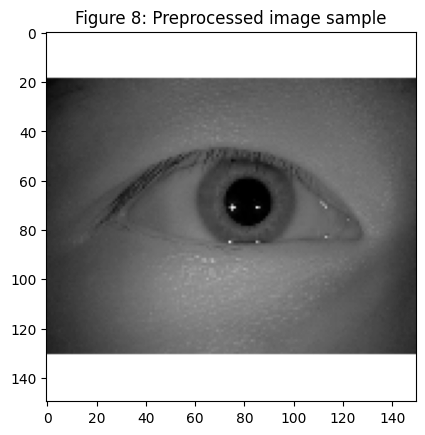

In [25]:
plt.imshow(preprocess_image(df.iloc[15]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

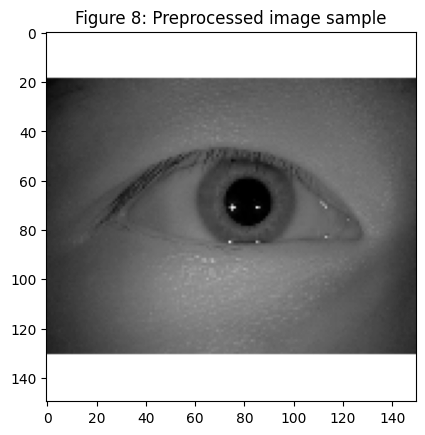

In [26]:
plt.imshow(preprocess_image(df.iloc[15]['ImagePath']), cmap="gray")
plt.title("Figure 8: Preprocessed image sample")
plt.show

In [27]:
def preprocess_labels(df):
    """
    Prepares labels for training indluding transform to string and then encode.
    Args: 
        df(pd.DataFrame): dataset non-encoded labels and images paths
    Rteurns:
        labels(np.array): prepared labels for training
    """
    labels = df['Label'].astype(str)
    le = LabelEncoder()
    le.fit(labels)
    labels = le.transform(labels)
    return labels

In [28]:
print("Label after encoding: ", preprocess_labels(df)[120])
print("Label before encoding: ",df.iloc[120]['Label'])

Label after encoding:  959
Label before encoding:  479-R


In [29]:
def split_dataset(preprocessed_images, preprocessed_labels, train_size=0.8, validation_size=0.1, shuffle=True):
    """
    Returns the splitted dataset using the 80:10:10 split rule (for deep learnig we do train split) Pareto principle
    Args:
        preprocessed_images()
        preprocessed_labels
    Returns:
        x_train(np.Array): training images
        x_valid(np.Array): validation images
        x_test(np.Array): testing images
        y_train(np.Array): training labels
        y_valid(np.Array): validation labels
        y_test(np.Array): testing labeles
    """
    np.random.seed(1190652)
    indices = np.arange(SIZE)
    if shuffle:
        np.random.shuffle(indices)
    
    train_samples = int(SIZE * train_size)
    validation_samples = int(SIZE * validation_size)
    
    train_indices = indices[:train_samples]
    validation_indices = indices[train_samples:train_samples + validation_samples]
    test_indices = indices[train_samples + validation_samples:]
    
    x_train  = preprocessed_images[train_indices]
    y_train = preprocessed_labels[train_indices]
    x_valid = preprocessed_images[validation_indices]
    y_valid = preprocessed_labels[validation_indices]
    x_test = preprocessed_images[test_indices]
    y_test = preprocessed_labels[test_indices]
    
    return x_train, x_valid, x_test, y_train, y_valid, y_test

In [30]:
def prepare_dataset(df):
    """
    Prepares the dataset to training and modeling
    Args:
        df(pd.DataFrame): the dataset
    Returns:
        x_train(np.Array): training images
        x_valid(np.Array): validation images
        x_test(np.Array): testing images
        y_train(np.Array): training labels
        y_valid(np.Array): validation labels
        y_test(np.Array): testing labeles
    """
    preprocessed_images = []
    for i in range(SIZE):
        image = preprocess_image(images[i])
        preprocessed_images.append(image)
    
    preprocessed_images = np.array(preprocessed_images , dtype=np.float32).reshape(-1, IMG_HEIGHT, IMG_WIDTH, NUM_CHANNELS)
    preprocessed_labels = preprocess_labels(df)
    return split_dataset(preprocessed_images, preprocessed_labels)

In [31]:
def batch_generator(df, batch_size):
    total_images = df.shape[0]
    for i in range(0, total_images, batch_size):
        batch_images = []
        for j in range(i, min(i + batch_size, total_images)):
            image = preprocess_image(df.loc[j, 'ImagePath'])
            batch_images.append(image)
        yield np.array(batch_images, dtype=np.float32)


In [32]:
def preprocess_image(image_path, target_size=(150, 150)):  # Set a smaller size
    image = PIL.Image.open(image_path)
    image = image.resize(target_size)  # Resize the image
    return np.array(image)


In [33]:
preprocessed_images = np.memmap('data.mmap', dtype=np.float32, mode='w+', shape=(20000, 150, 150, 1))


In [34]:
x_train, x_valid, x_test, y_train, y_valid, y_test = prepare_dataset(df)
print("Triaing set size: ", x_train.shape)
print("Validation set size: ", x_valid.shape)
print("Testing set size: ",x_test.shape)

Triaing set size:  (16000, 150, 150, 1)
Validation set size:  (2000, 150, 150, 1)
Testing set size:  (2000, 150, 150, 1)


In [35]:
class CentralCrop(Layer):
    def __init__(self, central_fraction=0.9):
        super(CentralCrop, self).__init__()
        self.central_fraction = central_fraction

    def call(self, inputs):
        cropped = tf.image.central_crop(inputs, central_fraction=self.central_fraction)
        return cropped

In [36]:
data_augmentation = keras.Sequential([
    Input(shape=input_shape),
    CentralCrop(central_fraction=0.9)  
])

augmented_images = data_augmentation(x_train)  

Encoded Person Label is: 516


<function matplotlib.pyplot.show(close=None, block=None)>

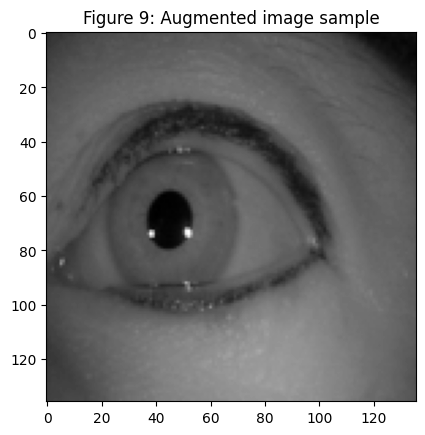

In [37]:
print(f'Encoded Person Label is: {y_valid[10]}')
plt.imshow(augmented_images[10], cmap="gray")
plt.title("Figure 9: Augmented image sample")
plt.show

In [39]:
#Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

def timeit(func):
    def wrapper(*args, **kwargs):
        start_time = time.time()
        result = func(*args, **kwargs)
        end_time = time.time()
        logging.info(f"{func.__name__} execution time: {end_time - start_time:.4f} seconds")
        return result
    return wrapper

@timeit
def rgb_to_grayscale(image):
    B, G, R = cv2.split(image)
    grayscale = 0.2989 * R + 0.5870 * G + 0.1140 * B
    return grayscale.astype(np.uint8)

@timeit
def contrast_stretching(image):
    min_val, max_val = np.min(image), np.max(image)
    stretched = ((image - min_val) / (max_val - min_val) * 255).astype(np.uint8)
    return stretched

@timeit
def adaptive_median_filter(image, max_kernel_size=7):
    std_dev = np.std(image)
    kernel_size = max(3, min(max_kernel_size, int(std_dev / 10) * 2 + 1))
    logging.info(f"Using kernel size: {kernel_size}x{kernel_size}")
    return cv2.medianBlur(image, kernel_size)

@timeit
def calculate_metrics(original, processed):
    mse_val = np.mean((original - processed) ** 2)
    psnr_val = 10 * np.log10((255.0 ** 2) / mse_val) if mse_val > 0 else float('inf')
    return mse_val, psnr_val

@timeit
def detect_pupil(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)
    rows = gray.shape[0]
    circles = cv2.HoughCircles(
        gray, 
        cv2.HOUGH_GRADIENT, 
        dp=1, 
        minDist=rows / 8, 
        param1=50, 
        param2=30, 
        minRadius=30, 
        maxRadius=50
    )
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            center = (i[0], i[1])
            radius = i[2]
            cv2.circle(image, center, radius, (0, 255, 0), 3)
            break  # Only use the first detected circle
        return image, True
    else:
        logging.warning("No circles detected")
        return image, False

@timeit
def process_and_save_image(image_path, output_dir, max_kernel_size=7):
    image = cv2.imread(image_path)
    if image is None:
        logging.error(f"Failed to load image: {image_path}")
        return

    logging.info(f"Processing image: {image_path}")
    image = cv2.resize(image, (320, 240))
    
    grayscale_image = rgb_to_grayscale(image)
    stretched_image = contrast_stretching(grayscale_image)
    filtered_image = adaptive_median_filter(stretched_image, max_kernel_size)

    mse_value, psnr_value = calculate_metrics(grayscale_image, filtered_image)
    logging.info(f'Mean Squared Error (MSE): {mse_value}')
    logging.info(f'Peak Signal-to-Noise Ratio (PSNR): {psnr_value} dB')

    pupil_image, pupil_detected = detect_pupil(image.copy())

    if pupil_detected:
        output_path = os.path.join(output_dir, os.path.basename(image_path))
        cv2.imwrite(output_path, pupil_image)
        logging.info(f"Saved detected pupil image: {output_path}")
    else:
        logging.info(f"No pupil detected in image: {image_path}")

@timeit
def process_dataset(parent_dir, output_dir, max_kernel_size=7):
    os.makedirs(output_dir, exist_ok=True)
    image_paths = glob(os.path.join(parent_dir, '**', '*.bmp'), recursive=True)
    logging.info(f"Found {len(image_paths)} images in {parent_dir}")

    for image_path in image_paths:
        process_and_save_image(image_path, output_dir, max_kernel_size)

if __name__ == "__main__":
    parent_dir = r'/kaggle/input/casia-iris-thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand'
    output_dir = r'/kaggle/working/'
    process_dataset(parent_dir, output_dir, max_kernel_size=9)

In [40]:
EPOCHS = 100
BATCH_SIZE = 32
loss = 'sparse_categorical_crossentropy'
# optimizer = 'adam'
activation = "leaky_relu"
initial_learning_rate = 0.0010000000474974513
optimizer = Adam(learning_rate=initial_learning_rate)

earlyStopping = EarlyStopping(monitor='val_loss', patience=10, verbose=0, mode='min')
mcp_save = ModelCheckpoint('.mdl_wts.keras', save_best_only=True, monitor='val_loss', mode='min')
reduce_lr_loss = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=7, verbose=1, epsilon=1e-4, mode='min')

In [41]:
def create_model():
    """
    Create the model architicure and compile it, call on pre-set values.
    Returns:
        model (keras.Sequential): a model compiled with its layers
    """
    padding = 'same'
    poolpadding = 'valid'

    model = Sequential([
        Input(input_shape),
        ####### Features extraction
        
        Conv2D(32, (5, 5), padding=padding, activation=activation, name="Conv1"),
        BatchNormalization(axis=-1, name="BN1"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool1"),
        GaussianNoise(0.1, name="GaussianNoise"), 
        Dropout(0.1, name="Dropout1"),

        Conv2D(64, (5, 5), padding=padding, activation=activation, name="Conv2"),
        BatchNormalization(axis=-1, name="BN2"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool2"),
        Dropout(0.1, name="Dropout2"),

        Conv2D(128, (5, 5), padding=padding, activation=activation, name="Conv3"),
        BatchNormalization(axis=-1, name="BN3"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool3"),
        Dropout(0.25, name="Dropout3"),

        Conv2D(256, (3, 3), padding=padding, activation=activation, name="Conv4"),
        BatchNormalization(axis=-1, name="BN4"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool4"),
        Dropout(0.25, name="Dropout4"),

        Conv2D(256, (3, 3), padding=padding, activation=activation, name="Conv5"),
        BatchNormalization(axis=-1, name="BN5"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool5"),
        Dropout(0.25, name="Dropout5"),
        
        Conv2D(512, (3, 3), padding=padding, activation=activation, name="Conv6"),
        BatchNormalization(axis=-1, name="BN6"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool6"),
        Dropout(0.45, name="Dropout6"),
        
        Conv2D(512, (2, 2), padding=padding, activation=activation, name="Conv7"),
        BatchNormalization(axis=-1, name="BN7"),  
        MaxPooling2D(pool_size=(2, 2), padding=poolpadding, name="Mpool7"),
        Dropout(0.5, name="Dropout7"),
        
        #### Flatten and fully connected layers, classifier using relu sofftmax
        Flatten(),
        Dense(128, activation=activation, name = "Dense1"),
        Dense(2000, activation='softmax', name="SoftmaxClasses"),
    ],
    name="IRISRecognizer")
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

    return model

In [42]:
model = create_model()
model.summary()

Model: "IRISRecognizer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1 (Conv2D)                  │ (None, 150, 150, 32)   │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN1 (BatchNormalization)        │ (None, 150, 150, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool1 (MaxPooling2D)           │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GaussianNoise (GaussianNoise)   │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout1 (Dropout)              │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 75, 75, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN2 (BatchNormalization)        │ (None, 75, 75, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool2 (MaxPooling2D)           │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout2 (Dropout)              │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 37, 37, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN3 (BatchNormalization)        │ (None, 37, 37, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool3 (MaxPooling2D)           │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout3 (Dropout)              │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv4 (Conv2D)                  │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN4 (BatchNormalization)        │ (None, 18, 18, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool4 (MaxPooling2D)           │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout4 (Dropout)              │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv5 (Conv2D)                  │ (None, 9, 9, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN5 (BatchNormalization)        │ (None, 9, 9, 256)      │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool5 (MaxPooling2D)           │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout5 (Dropout)              │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv6 (Conv2D)                  │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN6 (BatchNormalization)        │ (None, 4, 4, 512)      │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Mpool6 (MaxPooling2D)           │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout6 (Dropout)              │ (None, 2, 2, 512)      │             

 Total params: 3,702,224 (14.12 MB)

 Trainable params: 3,698,704 (14.11 MB)

 Non-trainable params: 3,520 (13.75 KB)

In [43]:
history = model.fit(np.array(x_train), y_train, validation_data=(np.array(x_valid), y_valid), epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[earlyStopping, mcp_save, reduce_lr_loss])

Epoch 1/100


I0000 00:00:1727039452.187963     128 service.cc:145] XLA service 0x798e20003e30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1727039452.188008     128 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1727039452.188011     128 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


  2/500 ━━━━━━━━━━━━━━━━━━━━ 33s 68ms/step - accuracy: 0.0000e+00 - loss: 7.9403   

I0000 00:00:1727039472.652667     128 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 51ms/step - accuracy: 0.0020 - loss: 7.5776 - val_accuracy: 0.0070 - val_loss: 7.1108 - learning_rate: 0.0010
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.0296 - loss: 6.0368 - val_accuracy: 0.0145 - val_loss: 6.8942 - learning_rate: 0.0010
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.1110 - loss: 4.6110 - val_accuracy: 0.1865 - val_loss: 4.1289 - learning_rate: 0.0010
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.2471 - loss: 3.4651 - val_accuracy: 0.0165 - val_loss: 9.4475 - learning_rate: 0.0010
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.3869 - loss: 2.5955 - val_accuracy: 0.1040 - val_loss: 6.0271 - learning_rate: 0.0010
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.5039 - loss: 1.9910 - val_accuracy: 0.4465 - val_loss: 2.4221 - learning_rate: 0.0010
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.6004 - loss: 

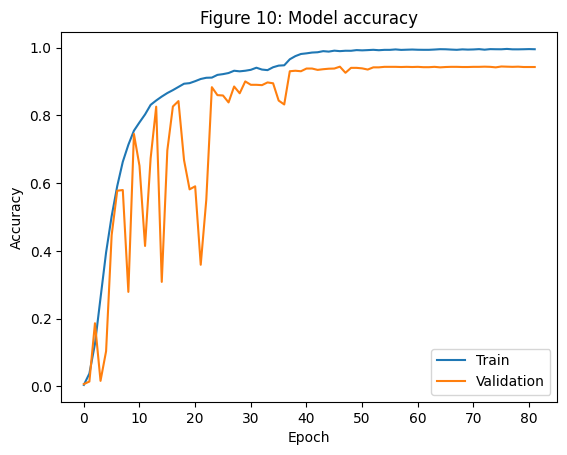

In [44]:
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Figure 10: Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

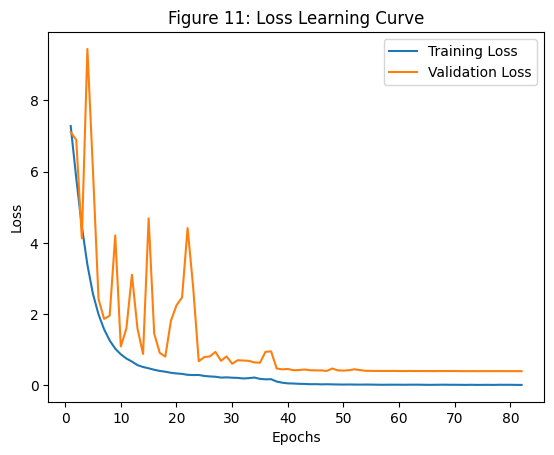

In [45]:
training_loss = history.history['loss']
validation_loss = history.history['val_loss']
epochs = range(1, len(training_loss) + 1)

plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')
plt.title('Figure 11: Loss Learning Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [46]:
model.save("IRISRecognizer.h5")
reconstructed_model = keras.models.load_model("IRISRecognizer.h5")
test_loss, test_acc = reconstructed_model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc*100:.3f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9350 - loss: 0.4681
Test accuracy: 94.300


In [47]:
def evaluate_model_visualize(dataset, y_true, model, class_names):
    """
    Make a sample and predict it using the model visualize outputs and calculate the accuracy.
    Args:
        - dataaset (np.array): x_test dataset
        - y_true (np.array): y_test dataset
        - model (keras.Sequential): weighted trained model
        - class_names (pd.Series): classes in the dataset
    Return:
        - Nothing.
    """
    num_rows = 4
    num_cols = 6
    data_batch = dataset[0:num_rows * num_cols]
    predictions = model.predict(data_batch)
    plt.figure(figsize=(20, 8))
    num_matches = 0

    for idx in range(num_rows * num_cols):
        ax = plt.subplot(num_rows, num_cols, idx + 1)
        plt.axis("off")
        plt.imshow(data_batch[idx], cmap="gray")

        pred_idx = np.argmax(predictions[idx])
        true_idx = y_true[idx]

        title = f"{class_names[true_idx]} : {class_names[pred_idx]}"
        title_obj = plt.title(title, fontdict={"fontsize": 13})

        if pred_idx == true_idx:
            num_matches += 1
            plt.setp(title_obj, color="g")
        else:
            plt.setp(title_obj, color="r")
    acc = num_matches / (num_rows * num_cols)
    print("Prediction accuracy: {:.2%}".format(acc))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Prediction accuracy: 95.83%


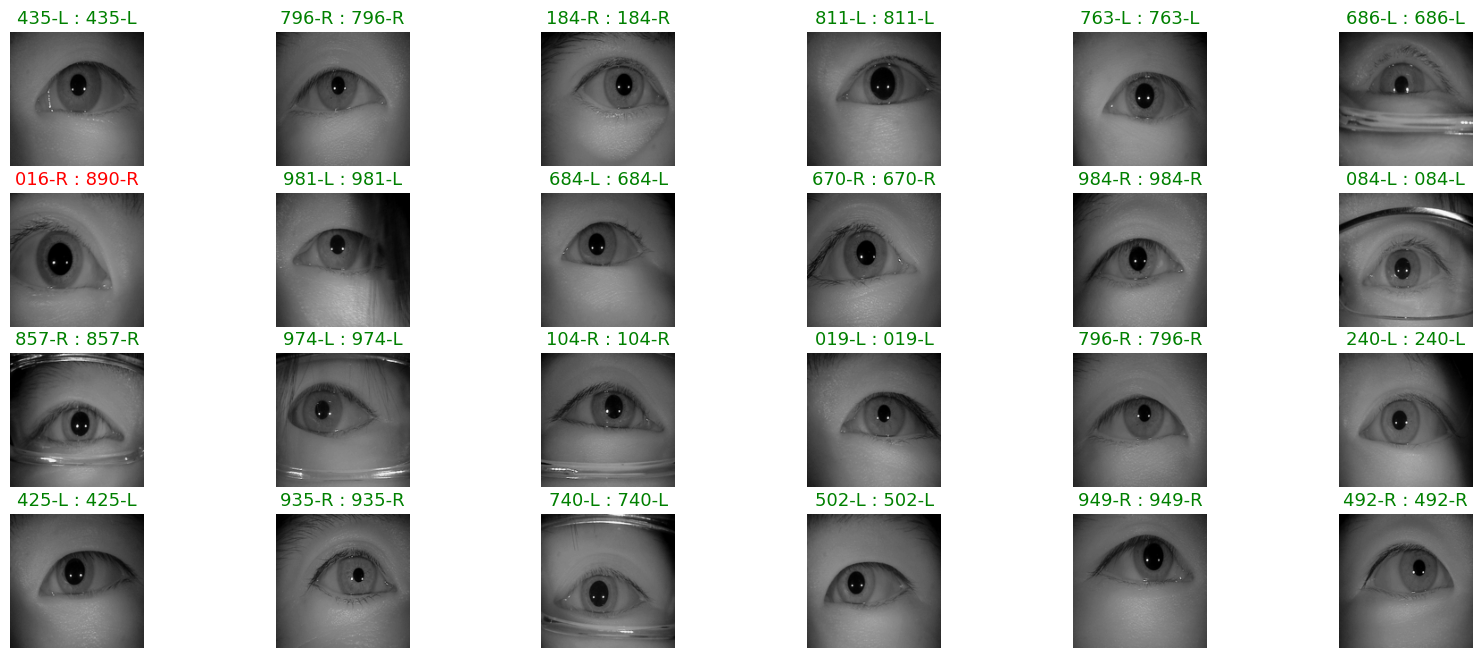

In [48]:
evaluate_model_visualize(x_test,y_test, reconstructed_model,df['Label'].unique())

In [49]:
def describe_model_confedince(reconstructed_model, x_test): 
    """
    This is to look into the distribution of the maximum liklihoods
    represnts the confidence levels of the how much the model is sure this is (the classification)
    Args:
        - reconstructed_model(keras.Sequential): trained weights
        - x_test(np.array): testing images
    Returns:
        Nothing, only prints statics about the max_liklihoods
    """
    probabilites = reconstructed_model.predict(x_test)
    y_pred = np.argmax(probabilites, axis=1)
    max_liklihoods = np.max(probabilites, axis=1)
    print("Average of (Maximum Liklihood) for predictions: ", np.average(max_liklihoods))
    print("Standard deviation of (Maximum Liklihood) for predictions: ", np.std(max_liklihoods))
    print("Median of (Maximum Liklihood) for predictions: ", np.median(max_liklihoods))
    print("Minimum of (Maximum Liklihood) for predictions: ", np.min(max_liklihoods))
    print("Maximum of (Maximum Liklihood) for predictions: ", np.max(max_liklihoods))
    threshold = np.max(max_liklihoods) - np.min(max_liklihoods)
    print("Chosen threshold is: ", threshold)
    return probabilites

In [50]:
probabilites = describe_model_confedince(reconstructed_model, x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
Average of (Maximum Liklihood) for predictions:  0.97076684
Standard deviation of (Maximum Liklihood) for predictions:  0.10591823
Median of (Maximum Liklihood) for predictions:  0.99999785
Minimum of (Maximum Liklihood) for predictions:  0.18709446
Maximum of (Maximum Liklihood) for predictions:  1.0
Chosen threshold is:  0.81290555


In [51]:
precision = Precision(task="multiclass", num_classes=2000)
recall = Recall(task="multiclass", num_classes=2000)
accuracy = Accuracy(task="multiclass", num_classes=2000)
maurc = AUROC(task="multiclass",num_classes=2000)

In [52]:
accuracyv = accuracy(torch.tensor(probabilites), torch.tensor(y_test))
prec = precision(torch.tensor(probabilites), torch.tensor(y_test))
rec = recall(torch.tensor(probabilites), torch.tensor(y_test))
aurc = maurc(torch.tensor(probabilites), torch.tensor(y_test))

/opt/conda/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: No positive samples in targets, true positive value should be meaningless. Returning zero tensor in true positive score
  warnings.warn(*args, **kwargs)  # noqa: B028


In [53]:
print(f"Accuracy: {accuracyv}")
print(f"Precision: {prec}")
print(f"Recall: {rec}")

Accuracy: 0.9430000185966492
Precision: 0.9430000185966492
Recall: 0.9430000185966492


In [54]:
fpr = dict()
tpr = dict()
roc_auc = dict()

num_classes = 2000

for i in range(num_classes):
    y_true_binary = np.where(y_test == i, 1, 0)
    fpr[i], tpr[i], _ = roc_curve(y_true_binary, probabilites[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

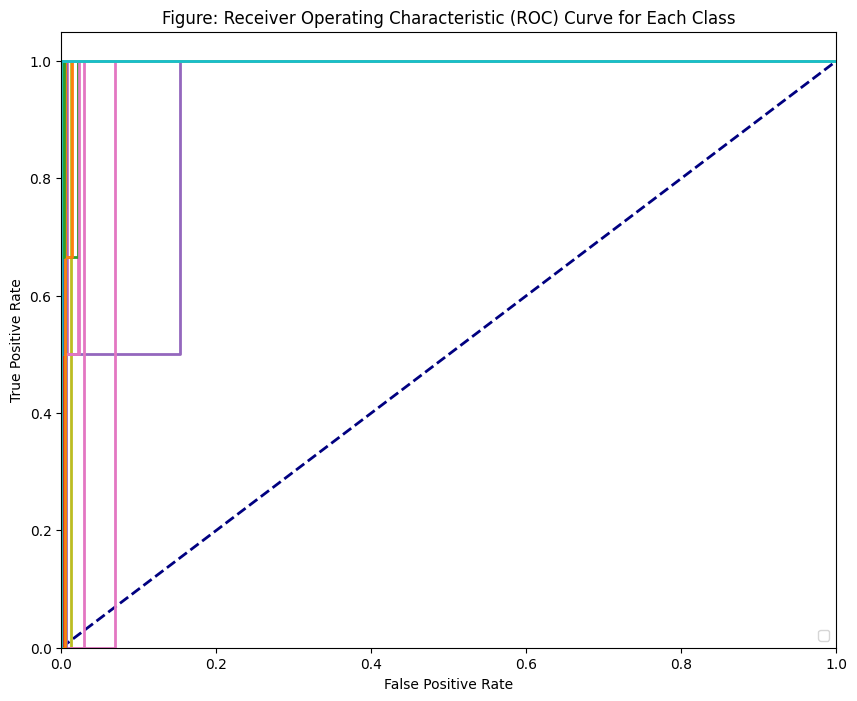

In [55]:
plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  ## this is the state of a random classifier

for i in range(num_classes):
    if not math.isnan(roc_auc[i]):
        plt.plot(fpr[i], tpr[i], lw=2)#, label=f'Class {i} (AUC = {roc_auc[i]:.2f})')
        
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Figure: Receiver Operating Characteristic (ROC) Curve for Each Class')
plt.legend(loc="lower right")
plt.show()

In [56]:
eer_thresholds = []

for i in range(num_classes):
    try:
        fpr_values = fpr[i]
        tpr_values = tpr[i]
        interp_fn = interp1d(fpr_values, tpr_values)
        def eer_fn(x):
            return 1.0 - x - interp_fn(x)

        eer_threshold = brentq(eer_fn, 0.0, 1.0)
        eer_thresholds.append(eer_threshold)
    except ValueError:
        continue

avg_eer_threshold = np.mean(eer_thresholds)
print(f"Equal Error Rate (EER) Threshold: {avg_eer_threshold:.4f}")

Equal Error Rate (EER) Threshold: 0.0003
